# Passo 1: Exploração
Carreguei a base de dados original e fiz uma análise exploratória inicial para entender a estrutura das colunas e medir a proporção exata de fraudes, confirmando o alto desequilíbrio típico desse tipo de problema.

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Carregando o dataset original
url = "http://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

print("Dimensões do DataFrame:", df.shape)
print("\nPrimeiras linhas:")
display(df.head())

print("\nProporção de fraudes na base:")
print(df["Class"].value_counts(normalize=True) * 100)

Dimensões do DataFrame: (284807, 31)

Primeiras linhas:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Proporção de fraudes na base:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


# Passo 2: Preparação
Como o tempo é um fator crítico em transações financeiras, ordenei a base cronologicamente e criei variáveis de comportamento temporal (como a diferença de tempo entre transações consecutivas e a média móvel dos valores). Em seguida, apliquei a transformação logarítmica no valor, padronizei as variáveis numéricas com o `StandardScaler`, preparei as técnicas de amostragem (`SMOTE` e `RandomUnderSampler`) e separei os dados em treino e teste utilizando `stratify` para manter a mesma proporção de fraudes em ambos os conjuntos.

In [10]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Ordenando por tempo para garantir a sequência correta das transações
df = df.sort_values(by="Time").reset_index(drop=True)

# Criando variáveis de comportamento temporal e logarítmica
df["Time_Diff"] = df["Time"].diff().fillna(0)
df["Amount_Rolling_Mean"] = df["Amount"].rolling(window=5, min_periods=1).mean()
df["Log_Amount"] = np.log1p(df["Amount"])

# Padronizando variáveis numéricas
scaler = StandardScaler()
num_cols = ["Time", "Amount", "Log_Amount", "Time_Diff", "Amount_Rolling_Mean"]
df[num_cols] = scaler.fit_transform(df[num_cols])

# Separando features (X) e target (y)
X = df.drop(columns=["Class"])
y = df["Class"]

# Divisão treino/teste estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Opcional: Aplicando SMOTE para balanceamento no treino
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Passo 3: Treinamento
Comecei treinando uma Regressão Logística simples como baseline. Em seguida, treinei um Random Forest com pesos balanceados nas classes e adicionei o XGBoost (`XGBClassifier`) configurado com o parâmetro `scale_pos_weight` para lidar com o desbalanceamento. Por fim, realizei uma busca de hiperparâmetros ampliada utilizando o `GridSearchCV` no Random Forest com foco estrito em maximizar o Recall da fraude.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

print("Treinando Baseline (Regressão Logística)...")
lr_baseline = LogisticRegression(random_state=42, max_iter=1000)
lr_baseline.fit(X_train, y_train)

print("Treinando Random Forest com pesos balanceados...")
rf_balanced = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
)
rf_balanced.fit(X_train, y_train)

print("Treinando XGBoost Classifier...")
# Calculando a proporção para o scale_pos_weight lidar com o desbalanceamento
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

xgb_model = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
)
xgb_model.fit(X_train, y_train)

print("Executando GridSearchCV para otimização de Hiperparâmetros (RF)...")
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    scoring="recall",  # Focado em maximizar o Recall de fraudes
    cv=3,
    n_jobs=-1,
)

# Usando apenas 30% do treino para o Grid Search
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=0.3, random_state=42, stratify=y_train
)
grid_search.fit(X_train_sample, y_train_sample)

best_rf = grid_search.best_estimator_
print(f"Melhores Hiperparâmetros: {grid_search.best_params_}")

Treinando Baseline (Regressão Logística)...
Treinando Random Forest com pesos balanceados...
Treinando XGBoost Classifier...
Executando GridSearchCV para otimização de Hiperparâmetros (RF)...
Melhores Hiperparâmetros: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}


# Passo 4: Avaliação
Avaliei todos os modelos no conjunto de teste construindo uma função personalizada de ajuste de limiar (threshold tuning). Utilizei a curva Precision-Recall para encontrar o ponto de corte ideal que maximiza o F1-Score da fraude, analisando em seguida o relatório de classificação completo e o ROC-AUC de cada algoritmo (incluindo o XGBoost).

In [12]:
from sklearn.metrics import (
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)


def evaluate_model_pipeline(model, X_t, y_t, name="Modelo"):
  probs = model.predict_proba(X_t)[:, 1]
  precision, recall, thresholds = precision_recall_curve(y_t, probs)
  f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
  best_threshold = thresholds[np.argmax(f1_scores)]

  preds = (probs >= best_threshold).astype(int)

  print(f"\n=== {name} (Melhor Threshold: {best_threshold:.4f}) ===")
  print(classification_report(y_t, preds))
  print(f"ROC-AUC: {roc_auc_score(y_t, probs):.4f}")
  return best_threshold


# Avaliando todos os modelos no conjunto de teste
evaluate_model_pipeline(
    lr_baseline, X_test, y_test, "Regressão Logística (Baseline)"
)
evaluate_model_pipeline(
    rf_balanced, X_test, y_test, "Random Forest (class_weight='balanced')"
)
evaluate_model_pipeline(xgb_model, X_test, y_test, "XGBoost Classifier")
evaluate_model_pipeline(
    best_rf, X_test, y_test, "Random Forest Otimizado (GridSearchCV)"
)


=== Regressão Logística (Baseline) (Melhor Threshold: 0.1425) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.74      0.81      0.77        98

    accuracy                           1.00     56962
   macro avg       0.87      0.90      0.89     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9580

=== Random Forest (class_weight='balanced') (Melhor Threshold: 0.2300) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.90      0.86      0.88        98

    accuracy                           1.00     56962
   macro avg       0.95      0.93      0.94     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9529

=== XGBoost Classifier (Melhor Threshold: 0.9040) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
       

np.float64(0.24995370898599859)

# Passo 5: Explicação
Por fim, utilizei a biblioteca SHAP para abrir a "caixa-preta" do melhor modelo treinado. Com base em uma amostra do conjunto de teste, gerei gráficos de interpretabilidade que revelam quais variáveis (incluindo as temporais criadas) pesaram mais em cada decisão de detecção de fraudes.

Gerando gráfico SHAP...


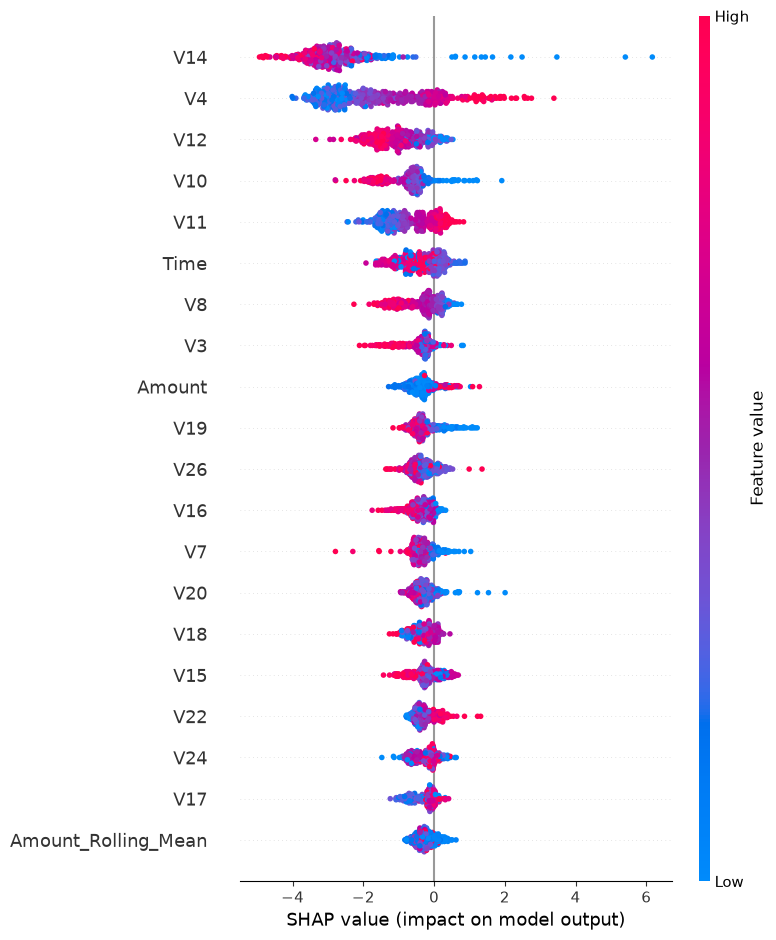

In [13]:
import shap

# Selecionando uma amostra do conjunto de teste para acelerar o cálculo do SHAP
X_test_sample = X_test.sample(n=500, random_state=42)

# Criando o explainer com base no XGBoost treinado
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_sample)

# Gerando o gráfico de resumo do SHAP (Summary Plot) para a classe de fraude
print("Gerando gráfico SHAP...")
shap.summary_plot(shap_values, X_test_sample)